# Biodiversity in US National Parks - A Codecademy Project

In this project, I downloaded data from Codecademy and worked to understand and analyze it using Python and various data visualization tools.
The project is based on data about different species and their conservation status across US national parks.

The United States has over 60 national parks across 30 states and two territories. These parks are home to different ecosystems, landscapes and wildlife.
Many of these parks are popular among nature-lovers, hikers and casual travelers alike, and accept millions of visitors every year.
But US national parks also play a significant role in conservation, as many of them focus on research to protect endangered species and restore ecosystems.
In this project, I analyzed data from four of these parks: Bryce Canyon (Utah), Great Smoky Mountains (Tennessee/North Carolina), Yellowstone (Wyoming/Montana/Idaho) and Yosemite (California).

I downloaded the available data from Codecademy for this project: two .csv files called “species_info” and “observations.” I also completed Codecademy's skill path, “Visualize Data with Python” in order to improve my data visualization skills.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
#Load csv files 
species_info = pd.read_csv('data/biodiversity/species_info.csv') 
observations = pd.read_csv('data/biodiversity/observations.csv')

In [3]:
#Quick look into species_info
species_info.head()

,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


In [4]:
#Quick look into observations
observations.head()

,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


Further investigation of the data

In [5]:
species_info.shape

(5824, 4)

In [6]:
observations.shape

(23296, 3)

The species_info file has 4 columns and observations file has 3 columns. These data frames have 5824 and 23296 rows, respectively.

Next I want to check if there are duplicates in the data. What do I consider a duplicate (and hence remove/clean)? In species_info, for me to consider something duplicated, at least the scientific and common names should be identical.
        This way, if there are multiple rows recorded of the same species, I can then check whether there are any differences in the other columns
        (i.e. same species but entries with different conservation status).</li>
In observations, on the other hand, the name and park information should be identical for me to check these rows (i.e. if the same species observed in the same park is accidentally stored in two separate instances.)

In [7]:
duplicate_species_info = species_info[species_info.duplicated(subset=['scientific_name', 'common_names'], keep=False)]
duplicate_count_species_info = duplicate_species_info.shape[0]
print(duplicate_count_species_info)
print(duplicate_species_info)

4
     category      scientific_name     common_names conservation_status
560      Fish  Oncorhynchus mykiss    Rainbow Trout                 NaN
3020   Mammal          Canis lupus  Gray Wolf, Wolf         In Recovery
3283     Fish  Oncorhynchus mykiss    Rainbow Trout          Threatened
4448   Mammal          Canis lupus  Gray Wolf, Wolf          Endangered


Seems like there are 2 duplicates where we have the same animal(same scientific name, same category, same common_names) but a different conservation status recorded. For example, is the "Canis lupus" in recovery or endangered ??  

In [8]:
duplicate_observations = observations[observations.duplicated(subset=['scientific_name', 'park_name'], keep=False)]
duplicate_count_observations = duplicate_observations.shape[0]
print(duplicate_observations)
print(duplicate_count_observations)

              scientific_name                            park_name  \
15              Lunaria annua  Great Smoky Mountains National Park   
22           Elodea nuttallii               Yosemite National Park   
25     Amaranthus retroflexus            Yellowstone National Park   
27          Scirpus cyperinus  Great Smoky Mountains National Park   
30           Glyceria striata               Yosemite National Park   
...                       ...                                  ...   
23258    Microtus longicaudus            Yellowstone National Park   
23259         Agrostis scabra                  Bryce National Park   
23267      Oxalis corniculata               Yosemite National Park   
23273      Dactylis glomerata                  Bryce National Park   
23280      Botrychium simplex            Yellowstone National Park   

       observations  
15               65  
22              158  
25              247  
27               73  
30              117  
...             ...  
23258

Observations data is trickier; there are 2228 duplicates based on scientific_name and park_name. What would be different in this case can only be the number of observations. I'd like to eliminate all rows where observations, too, is the exact same, so I can investigate the rest of the rows and try to understand why these duplicates exist. 

In [9]:
#I am copy pasting the same code as above, but this time also checking the observations column.
duplicate_observations = observations[observations.duplicated(subset=['scientific_name', 'park_name', 'observations'], keep=False)]
duplicate_count_observations = duplicate_observations.shape[0]
print(duplicate_observations)
print(duplicate_count_observations)

              scientific_name                            park_name  \
365            Plantago major  Great Smoky Mountains National Park   
513             Arctium minus               Yosemite National Park   
627        Spilogale putorius            Yellowstone National Park   
1020     Eleocharis palustris  Great Smoky Mountains National Park   
1032      Hesperis matronalis                  Bryce National Park   
1454   Echinochloa crus-galli  Great Smoky Mountains National Park   
1635    Streptopelia decaocto            Yellowstone National Park   
4178     Monotropa hypopithys  Great Smoky Mountains National Park   
4527   Botrychium virginianum            Yellowstone National Park   
7219        Prunella vulgaris  Great Smoky Mountains National Park   
7263   Echinochloa crus-galli  Great Smoky Mountains National Park   
8710    Streptopelia decaocto            Yellowstone National Park   
10038          Plantago major  Great Smoky Mountains National Park   
10674           Arct

There are 30 rows where all parameters are exactly the same. This means these rows are duplicates and can be cleaned up. 

In [10]:
#Removing these duplicates from the original observations data frame
observations_cleaned = observations.drop_duplicates(subset=['scientific_name', 'park_name', 'observations'], keep = 'first')
observations_cleaned.shape

(23281, 3)

Does this make sense? My initial observations data frame contained 23296 rows, and I identified 30 duplicates. When I keep the first occurrence of each and delete the duplicate row, I should get rid of 15 rows. 23296-15=23281, which is the number of rows of observations_cleaned, so it makes sense! I can also confirm this with the following line of code, which should output True:

In [11]:
observations.shape[0] - observations_cleaned.shape[0] == 15

True

In [12]:
observations = observations_cleaned

So now, in the observations data frame, we are left with data that may contain rows referring to the same animal/plant in the same parks, but have a different observation value. Here, I will take the average of all recorded values and use this value in my aggregated data.

So, I will get rid of these repetitive rows and combine the observation values for each duplicate. 

In [13]:
#Aggregate
observations_aggr = observations_cleaned.groupby(['scientific_name', 'park_name'], as_index=False).agg({'observations': 'mean'})
observations_aggr.shape

(22164, 3)

In [14]:
observations = observations_aggr
observations_aggr.head()

,scientific_name,park_name,observations
0,Abies bifolia,Bryce National Park,109.0
1,Abies bifolia,Great Smoky Mountains National Park,72.0
2,Abies bifolia,Yellowstone National Park,215.0
3,Abies bifolia,Yosemite National Park,136.0
4,Abies concolor,Bryce National Park,83.0


Now the observations data is cleaned of all duplicates. Going back to the problem of duplicates in the species_info data... My first question to answer will be: Why would a species have different conservation statuses reported? This data frame is simple with only 2 such cases so I can look at both cases.

The first inconsistency is for "Rainbow Trout," where one row states that it is threatened, and the other row has NaN as the conservation status. The second inconsistency is for "Gray Wolf," where one row marks it as endangered and the other states it is in recovery. 

For the trout I will assume that it is threatened since the other data point doesn't provide any valuable or significant information (it is rather a lack of information, so I am choosing to remove the NaN value). For the wolf, I am hesitant to make a choice between endangered and in recovery, so I will join these two together in one row to represent both statuses.

In [15]:
#Define a function that can do this concatenation of conservation statuses and remove the NaN:
def concatenate_conservation_status(conservation_status):
    unique_row = sorted(set(conservation_status.dropna()))
    return ', '.join(unique_row)

#Now input into this function the duplicates you want to work with from species_info. Remember these were saved in duplicate_species_info.
consolidated_conservation_statuses = duplicate_species_info.groupby('scientific_name')['conservation_status'].apply(concatenate_conservation_status).reset_index()
consolidated_conservation_statuses

,scientific_name,conservation_status
0,Canis lupus,"Endangered, In Recovery"
1,Oncorhynchus mykiss,Threatened


The two inconsistent species are now resolved. But while checking for duplicates I only looked for rows where both the scientific name *and* the common names are identical. If I check the scientific name alone, many more species turn up more than once, usually because the same species was entered again under a slightly different common name (for example "Gray Wolf" and "Gray Wolf, Wolf").

This matters: when I later merge species_info with observations on scientific_name, every extra row for a species would copy that species' observations again, so they would be counted twice (or three times). To avoid this, I will collapse species_info so that each scientific name appears only once, combining the common names and using the consolidated conservation statuses from above.

In [16]:
#How many species are listed more than once?
repeated = species_info[species_info.duplicated(subset=['scientific_name'], keep=False)]
print(repeated['scientific_name'].nunique(), "species appear in more than one row")

#Combine the common names of repeated rows, without repeating any name
def combine_common_names(names):
    unique_names = []
    for entry in names:
        for name in entry.split(', '):
            if name not in unique_names:
                unique_names.append(name)
    return ', '.join(unique_names)

#Keep one row per species
species_info = species_info.groupby('scientific_name', as_index=False).agg({
    'category': 'first',
    'common_names': combine_common_names,
    'conservation_status': concatenate_conservation_status,
})
species_info['conservation_status'] = species_info['conservation_status'].replace('', np.nan)
species_info = species_info[['category', 'scientific_name', 'common_names', 'conservation_status']]

print(species_info.shape)
species_info[species_info['scientific_name'].isin(['Canis lupus', 'Oncorhynchus mykiss'])]

274 species appear in more than one row


(5541, 4)


,category,scientific_name,common_names,conservation_status
804,Mammal,Canis lupus,"Gray Wolf, Wolf","Endangered, In Recovery"
3430,Fish,Oncorhynchus mykiss,Rainbow Trout,Threatened


Now both observations and species_info are cleaned from duplicates, with exactly one row per species in species_info. To start investigating this further, the column called "category" in species_info really intrigued me: how many categories are there, what are they, and do any of them stand out in any way?

In [17]:
categories = species_info['category'].unique()
print(categories)

<StringArray>
[   'Vascular Plant', 'Nonvascular Plant',              'Bird',
         'Amphibian',           'Reptile',            'Mammal',
              'Fish']
Length: 7, dtype: str


In [18]:
category_counts = species_info['category'].value_counts().reset_index()
category_counts.columns = ['category', 'species_count']
category_counts

,category,species_count
0,Vascular Plant,4262
1,Bird,488
2,Nonvascular Plant,333
3,Mammal,176
4,Fish,125
5,Amphibian,79
6,Reptile,78


([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Vascular Plant'),
  Text(1, 0, 'Bird'),
  Text(2, 0, 'Nonvascular Plant'),
  Text(3, 0, 'Mammal'),
  Text(4, 0, 'Fish'),
  Text(5, 0, 'Amphibian'),
  Text(6, 0, 'Reptile')])

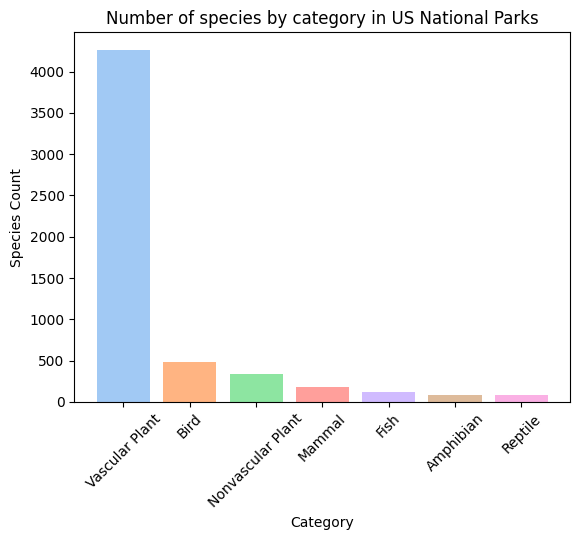

In [19]:
colors = sns.color_palette("pastel", len(category_counts))
plt.bar(category_counts['category'], category_counts['species_count'], color=colors)
#Edit axes and title:
plt.xlabel('Category')
plt.ylabel('Species Count')
plt.title('Number of species by category in US National Parks')
plt.xticks(rotation=45)

There are so many more vascular plant species recorded than species in other categories. But does that mean there are more vascular plants observed than other species in general? It is reasonable to assume so, however it could also be that although vascular plants includes more number of species, they are rare compared to other species and therefore not observed at a much higher frequency. I will check which is the case.

I want to plot categories once again, but this time looking at observations rather than species count. But the information I need for this graph is split across two data frames. I will first merge them on the column that's common between them, which is scientific_name. 

In [20]:
#Merge first
merged_data = pd.merge(observations, species_info[['scientific_name', 'category']], on='scientific_name', how='left')
category_first = ['category'] + [column for column in merged_data if column != 'category']
merged_data = merged_data[category_first]
merged_data

,category,scientific_name,park_name,observations
0,Vascular Plant,Abies bifolia,Bryce National Park,109.0
1,Vascular Plant,Abies bifolia,Great Smoky Mountains National Park,72.0
2,Vascular Plant,Abies bifolia,Yellowstone National Park,215.0
3,Vascular Plant,Abies bifolia,Yosemite National Park,136.0
4,Vascular Plant,Abies concolor,Bryce National Park,83.0
...,...,...,...,...
22159,Nonvascular Plant,Zygodon viridissimus,Yosemite National Park,159.0
22160,Nonvascular Plant,Zygodon viridissimus var. rupestris,Bryce National Park,102.0
22161,Nonvascular Plant,Zygodon viridissimus var. rupestris,Great Smoky Mountains National Park,102.0
22162,Nonvascular Plant,Zygodon viridissimus var. rupestris,Yellowstone National Park,237.0


([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Vascular Plant'),
  Text(1, 0, 'Bird'),
  Text(2, 0, 'Nonvascular Plant'),
  Text(3, 0, 'Mammal'),
  Text(4, 0, 'Fish'),
  Text(5, 0, 'Amphibian'),
  Text(6, 0, 'Reptile')])

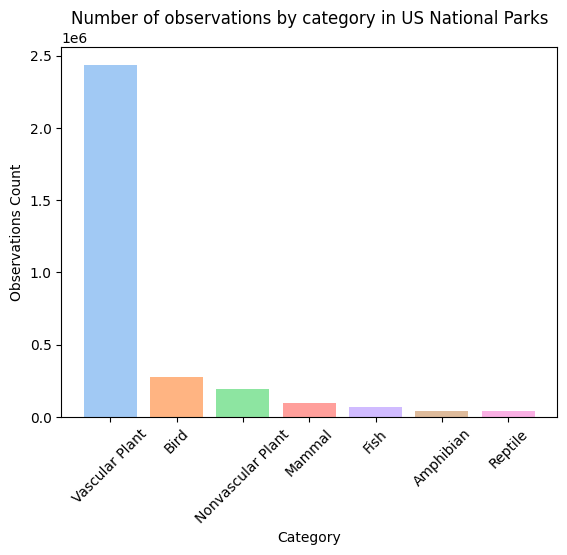

In [21]:
#Create a count of observations for each category, just like we did with category_counts above
category_observations = merged_data.groupby('category')['observations'].sum().reset_index()
#Need to make sure categories are ordered in the same way so our graphs are consistent
category_observations = pd.merge(category_observations, category_counts, on='category')
category_observations = category_observations.sort_values(by='species_count', ascending=False)

plt.bar(category_observations['category'], category_observations['observations'], color = colors)

#Edit axes and title:
plt.xlabel('Category')
plt.ylabel('Observations Count')
plt.title('Number of observations by category in US National Parks')
plt.xticks(rotation=45)

As expected, the number of observations per category does indeed correspond to the number of species per category. However, it's important to ask whether there are differences in the amount of observations per species. In other words: is there more observations of the category vascular plants because it simply has more species, or are vascular plant species actually more frequent than species of other categories? A simplified example would be if there were 10 vascular plant species, each observed 2 times and 2 fish species, each observed 5 times. The vascular plants overall would have an observation count of 20 as opposed to 10 observations of fish, but the fish species were each observed more times. I want to see what the data looks like when we consider individual species as opposed to broad categories.

In [22]:
full_merge = pd.merge(species_info, observations, on='scientific_name', how='left')
full_merge

,category,scientific_name,common_names,conservation_status,park_name,observations
0,Vascular Plant,Abies bifolia,Rocky Mountain Alpine Fir,NaN,Bryce National Park,109.0
1,Vascular Plant,Abies bifolia,Rocky Mountain Alpine Fir,NaN,Great Smoky Mountains National Park,72.0
2,Vascular Plant,Abies bifolia,Rocky Mountain Alpine Fir,NaN,Yellowstone National Park,215.0
3,Vascular Plant,Abies bifolia,Rocky Mountain Alpine Fir,NaN,Yosemite National Park,136.0
4,Vascular Plant,Abies concolor,"Balsam Fir, Colorado Fir, Concolor Fir, Silver...",NaN,Bryce National Park,83.0
...,...,...,...,...,...,...
22159,Nonvascular Plant,Zygodon viridissimus,Zygodon Moss,NaN,Yosemite National Park,159.0
22160,Nonvascular Plant,Zygodon viridissimus var. rupestris,Zygodon Moss,NaN,Bryce National Park,102.0
22161,Nonvascular Plant,Zygodon viridissimus var. rupestris,Zygodon Moss,NaN,Great Smoky Mountains National Park,102.0
22162,Nonvascular Plant,Zygodon viridissimus var. rupestris,Zygodon Moss,NaN,Yellowstone National Park,237.0


In [23]:
def find_avg_obs(category):
    rows_in_category = full_merge[full_merge['category'] == category]
    avg_obs_species = rows_in_category['observations'].mean()
    return avg_obs_species

In [24]:
#Example using Mammal:
find_avg_obs('Mammal')

np.float64(136.28882575757578)

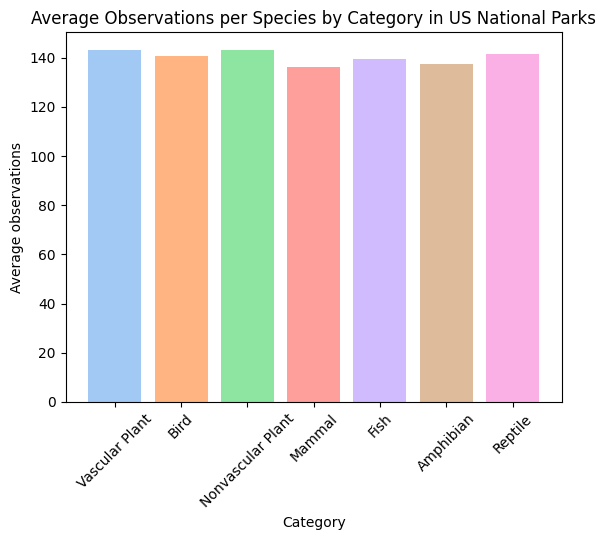

In [25]:
avg_obs_per_category = []
categories = ['Vascular Plant', 'Bird', 'Nonvascular Plant', 'Mammal', 'Fish', 'Amphibian', 'Reptile'] #this is a list we can iterate through!
for category in categories: 
    avg_obs = find_avg_obs(category)
    avg_obs_per_category.append(avg_obs)

plt.bar(categories, avg_obs_per_category, color=colors)

plt.xlabel('Category')
plt.ylabel('Average observations')
plt.title('Average Observations per Species by Category in US National Parks')
plt.xticks(rotation=45)
plt.show()

Now it's clear that even though vascular plants had a lot more observations than other categories, it was due to it having more species within it; the observations per species are very similar across all categories.

But how do the parks play into all of this? Let's add another layer and investigate how these observations are distributed across parks. First, I want to see the total count of observations for every category in every park.

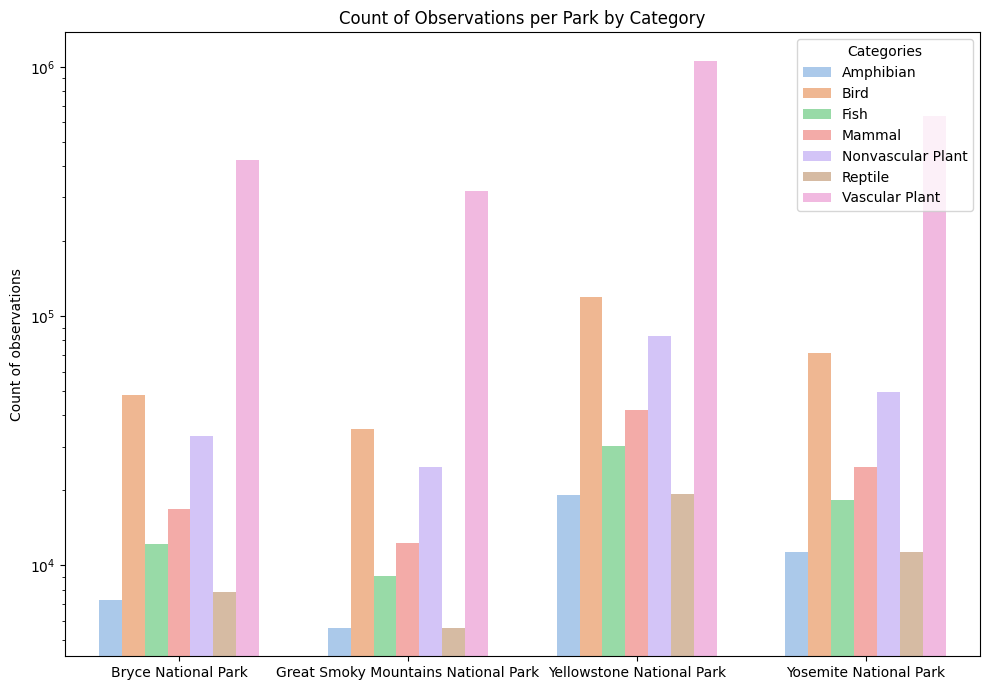

In [26]:
grouped = full_merge.groupby(['park_name', 'category'])['observations'].sum().reset_index()

plt.figure(figsize=(10,7))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.barplot(
    x=grouped['park_name'],
    y=grouped['observations'],
    hue=grouped['category'],
    dodge=True,
    width = 0.7,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yscale('log')
plt.ylabel('Count of observations')
plt.title('Count of Observations per Park by Category')
plt.legend(title='Categories')
plt.tight_layout()
plt.show()

According to this graph, vascular plants have more observations across all parks (makes sense), followed by birds, nonvascular plants and mammals. Yellowstone National Park has the most number of observations overall. 

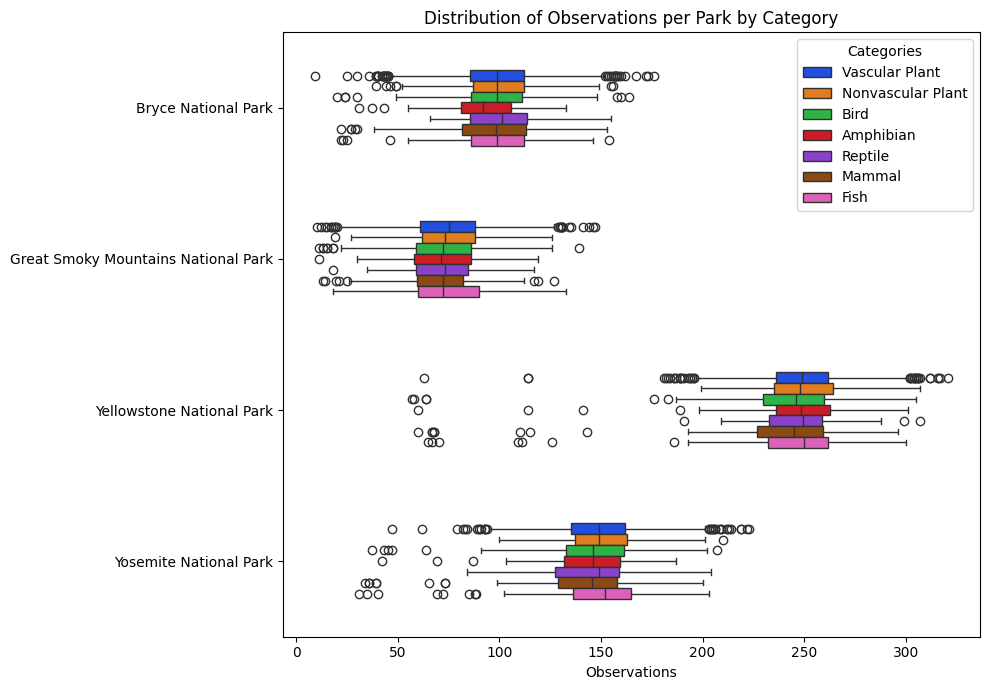

In [27]:
#How are observations distributed?
plt.figure(figsize=(10,7))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.boxplot(
    x=full_merge['observations'],
    y=full_merge['park_name'],
    hue=full_merge['category'],
    dodge=True,
    width = 0.5,
    palette='bright'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xlabel('Observations')
plt.title('Distribution of Observations per Park by Category')
plt.legend(title='Categories')
plt.tight_layout()
plt.show()

Here, we can see more clearly that Yellowstone is the park with the most observations, followed by Yosemite.

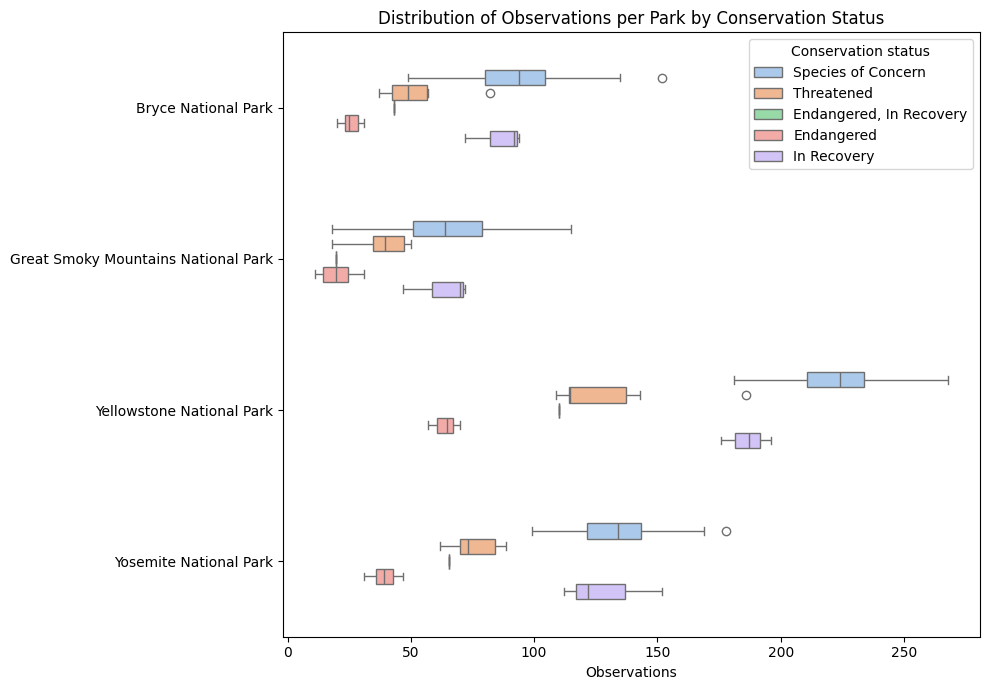

In [28]:
plt.figure(figsize=(10,7))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.boxplot(
    x=full_merge['observations'],
    y=full_merge['park_name'],
    hue=full_merge['conservation_status'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xlabel('Observations')
plt.title('Distribution of Observations per Park by Conservation Status')
plt.legend(title='Conservation status')
plt.tight_layout()
plt.show()

This is an interesting graph because while we confirm that Yellowstone has most observations across all conservation status groups, we can also see the distribution of different conservation statuses observed across parks. It seems like Yellowstone has a lot of species of concern observed, however it's important to remember that Yellowstone also has the greatest overall observations, so before making any conclusions I would like to see the same graph, normalized to the total number of observations in each park. 

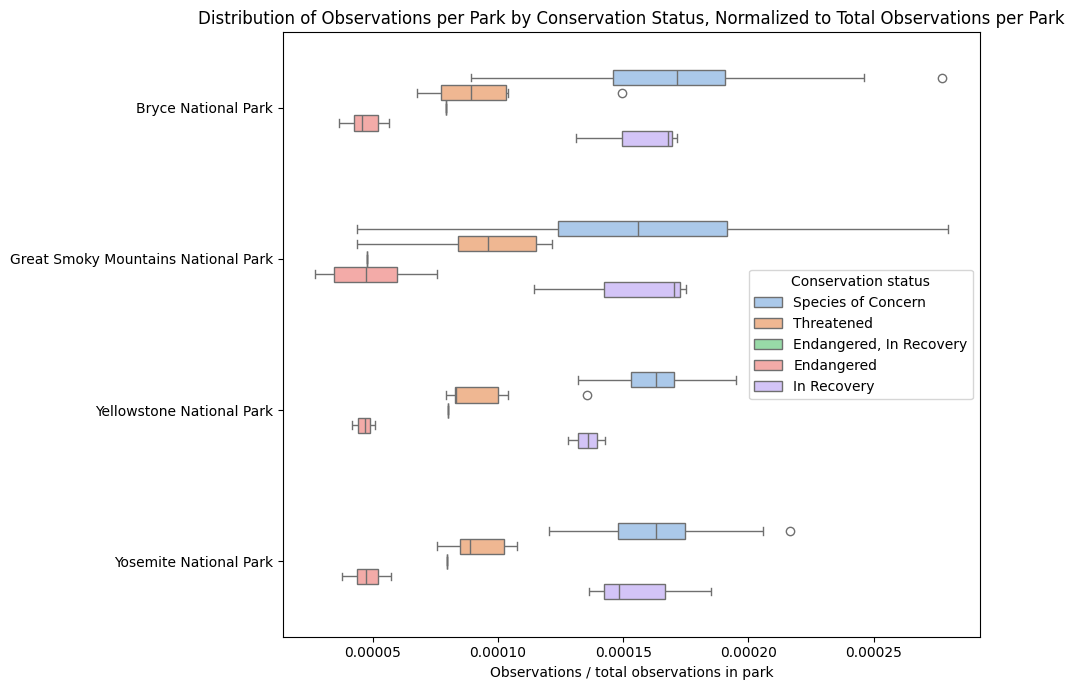

In [29]:
total_obs_per_park = full_merge.groupby('park_name')['observations'].sum().reset_index()
total_obs_per_park.columns = ['park_name', 'total_observations']

full_merge_normalized = pd.merge(full_merge, total_obs_per_park, on='park_name')
full_merge_normalized['normalized_observations'] = full_merge_normalized['observations'] / full_merge_normalized['total_observations']

plt.figure(figsize=(10,7))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.boxplot(
    x=full_merge_normalized['normalized_observations'],
    y=full_merge_normalized['park_name'],
    hue=full_merge_normalized['conservation_status'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xlabel('Observations / total observations in park')
plt.title('Distribution of Observations per Park by Conservation Status, Normalized to Total Observations per Park')
plt.legend(title='Conservation status')
plt.tight_layout()
plt.show()

This is now better! With the data normalized to overall observations per park, we can see that the species of concern observed in Yellowstone aren't so different than those in other parks. However, in every park, a typical species of concern is observed most often, followed by species in recovery, threatened species, and finally of course, endangered species.

Now I want to once again take a look at the categories of species.

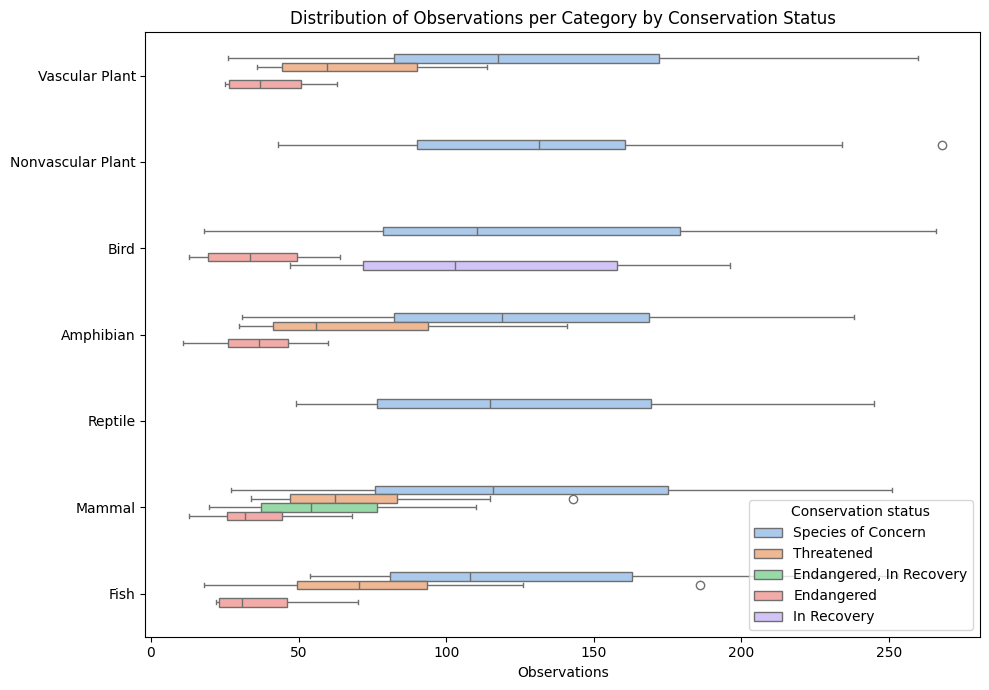

In [30]:
plt.figure(figsize=(10,7))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.boxplot(
    x=full_merge['observations'],
    y=full_merge['category'],
    hue=full_merge['conservation_status'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xlabel('Observations')
plt.title('Distribution of Observations per Category by Conservation Status')
plt.legend(title='Conservation status')
plt.tight_layout()
plt.show()

This is interesting, because it seems like not every category contains species of each conservation status, which is good to know! There are species of concern in every category, however nonvascular plants don't have any observations for species of other conservation statuses, and the only categories that have observations of species 'in recovery' are birds and mammals (for mammals, this is the gray wolf, whose status I combined earlier as 'Endangered, In Recovery'). 

In [31]:
#Let's confirm that this is the case by checking one example: whether nonvascular plants are all 'species of concern'
nonvascular_plants = full_merge[full_merge['category']=='Nonvascular Plant']
nonvascular_plants_conservation = nonvascular_plants['conservation_status'].unique()
print(nonvascular_plants_conservation)

<StringArray>
[nan, 'Species of Concern']
Length: 2, dtype: str


It seems like there are species of nonvascular plants that do not have a conservation status specified, indicated by "nan." This is good to know because despite what we saw on the graph, now we know that not every single species reported for nonvascular plants is necessarily species of concern, but we don't have the necessary information to include these species in another group. So, I will keep these rows in the data frame, but naturally, they won't be included in any analysis that focuses on conservation status.

The same might be true for other categories, but I will apply the same approach to each. 

Now, I wish to narrow down my analysis a little bit. The categories that interest me the most, based on this graph, are the mammals and bird; the mammals because they uniquely contain species observations from each conservation status, and birds because they seem to have many species in recovery, which is a conservation status I find to be interesting.

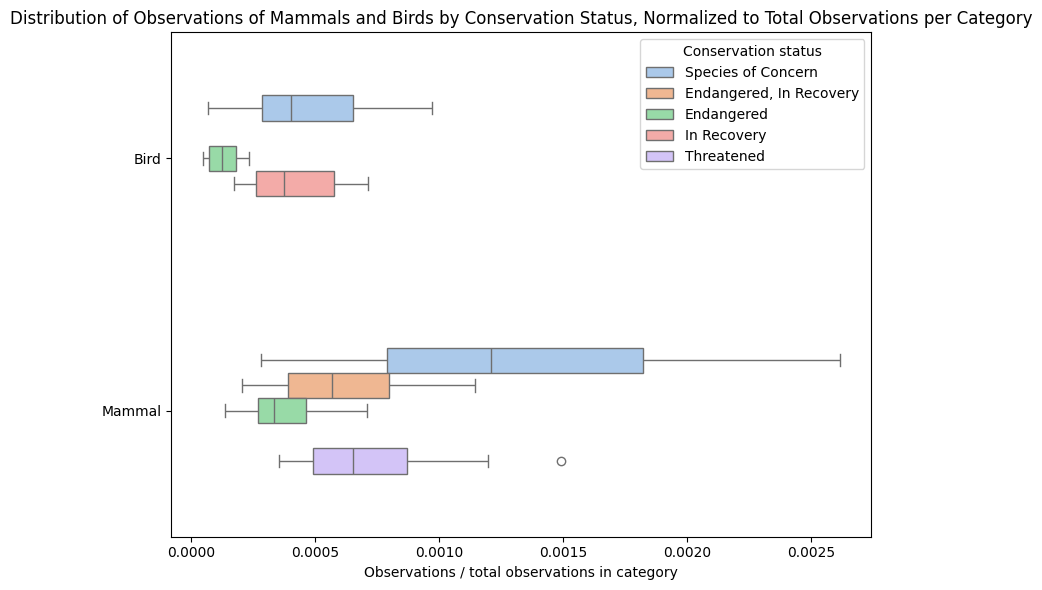

In [32]:
total_obs_per_category = full_merge.groupby('category')['observations'].sum().reset_index()
total_obs_per_category.columns = ['category', 'total_observations']

full_merge_normalized = pd.merge(full_merge, total_obs_per_category, on='category')
full_merge_normalized['normalized_observations'] = full_merge_normalized['observations'] / full_merge_normalized['total_observations']

mammal_and_bird = full_merge_normalized[full_merge_normalized['category'].isin(['Bird', 'Mammal'])]

plt.figure(figsize=(8,6))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.boxplot(
    x=mammal_and_bird['normalized_observations'],
    y=mammal_and_bird['category'],
    hue=mammal_and_bird['conservation_status'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xlabel('Observations / total observations in category')
plt.title('Distribution of Observations of Mammals and Birds by Conservation Status, Normalized to Total Observations per Category')
plt.legend(title='Conservation status')
plt.tight_layout()
plt.show()

Looking at this normalized distribution of mammal and bird species, I find it interesting once again that birds have this population of species in recovery. I will narrow down my analysis even more and focus now on better understanding these species of birds.

In [33]:
birds = full_merge[full_merge['category']=='Bird']
birds_total_obs = birds['observations'].sum()
birds

,category,scientific_name,common_names,conservation_status,park_name,observations
40,Bird,Acanthus flammea,"Common Redpoll, Redpoll",NaN,Bryce National Park,95.0
41,Bird,Acanthus flammea,"Common Redpoll, Redpoll",NaN,Great Smoky Mountains National Park,68.0
42,Bird,Acanthus flammea,"Common Redpoll, Redpoll",NaN,Yellowstone National Park,241.0
43,Bird,Acanthus flammea,"Common Redpoll, Redpoll",NaN,Yosemite National Park,120.0
44,Bird,Accipiter cooperii,Cooper's Hawk,Species of Concern,Bryce National Park,95.0
...,...,...,...,...,...,...
22151,Bird,Zonotrichia leucophrys oriantha,Mountain White-Crowned Sparrow,NaN,Yosemite National Park,135.0
22152,Bird,Zonotrichia querula,Harris's Sparrow,NaN,Bryce National Park,105.0
22153,Bird,Zonotrichia querula,Harris's Sparrow,NaN,Great Smoky Mountains National Park,83.0
22154,Bird,Zonotrichia querula,Harris's Sparrow,NaN,Yellowstone National Park,268.0


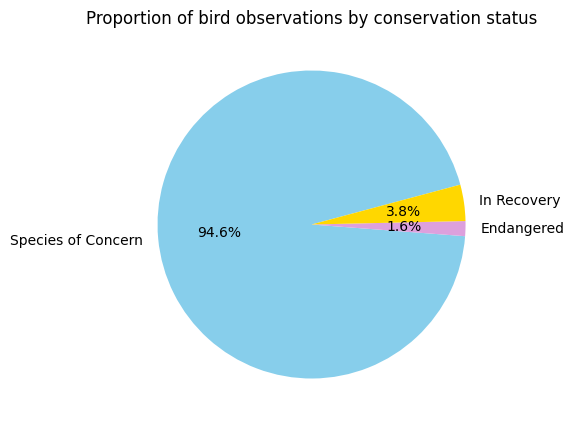

In [34]:
def find_total_obs(cons_status):
    rows_in_cons_status = birds[birds['conservation_status'] == cons_status]
    total_obs = rows_in_cons_status['observations'].sum()
    return total_obs

#I know already that birds have 3 different recorded conservation statuses (ignoring any NAN values)
birds_conservation = ['Species of Concern', 'Endangered', 'In Recovery']
birds_conservation_obs = []
for cons in birds_conservation:
    total_observations = find_total_obs(cons)
    birds_conservation_obs.append(total_observations)

colors = ['skyblue', 'plum', 'gold']

plt.figure(figsize=(5,5))
plt.pie(
    birds_conservation_obs,
    labels=birds_conservation,
    colors=colors,
    autopct='%1.1f%%',
    startangle=15,
)

plt.title('Proportion of bird observations by conservation status')
plt.show()

In [35]:
birds_in_recovery = birds[birds['conservation_status']=='In Recovery']
birds_in_recovery

,category,scientific_name,common_names,conservation_status,park_name,observations
8452,Bird,Falco peregrinus anatum,American Peregrine Falcon,In Recovery,Bryce National Park,72.0
8453,Bird,Falco peregrinus anatum,American Peregrine Falcon,In Recovery,Great Smoky Mountains National Park,70.0
8454,Bird,Falco peregrinus anatum,American Peregrine Falcon,In Recovery,Yellowstone National Park,176.0
8455,Bird,Falco peregrinus anatum,American Peregrine Falcon,In Recovery,Yosemite National Park,152.0
9384,Bird,Haliaeetus leucocephalus,Bald Eagle,In Recovery,Bryce National Park,94.0
9385,Bird,Haliaeetus leucocephalus,Bald Eagle,In Recovery,Great Smoky Mountains National Park,72.0
9386,Bird,Haliaeetus leucocephalus,Bald Eagle,In Recovery,Yellowstone National Park,187.0
9387,Bird,Haliaeetus leucocephalus,Bald Eagle,In Recovery,Yosemite National Park,112.0
14376,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Bryce National Park,92.0
14377,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Great Smoky Mountains National Park,47.0


As shown, there are 12 instances recorded as birds in recovery. However, this does not mean 12 species; as we can observe simply by looking at the table, there are only 3 species in recovery: the bald eagle, the American Peregrine Falcon and the Brown Pelican.

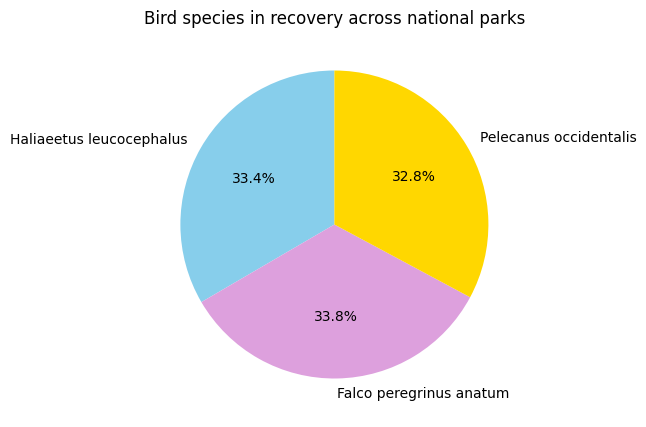

In [36]:
def find_total_obs(species):
    rows_species = birds[birds['scientific_name'] == species]
    total_obs = rows_species['observations'].sum()
    return total_obs

bird_species = ['Haliaeetus leucocephalus', 'Falco peregrinus anatum', 'Pelecanus occidentalis']
bird_species_obs = []
for bird in bird_species:
    total_observations = find_total_obs(bird)
    bird_species_obs.append(total_observations)

colors = ['skyblue', 'plum', 'gold']

plt.figure(figsize=(5,5))
plt.pie(
    bird_species_obs,
    labels=bird_species,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
)

plt.title('Bird species in recovery across national parks')
plt.show()

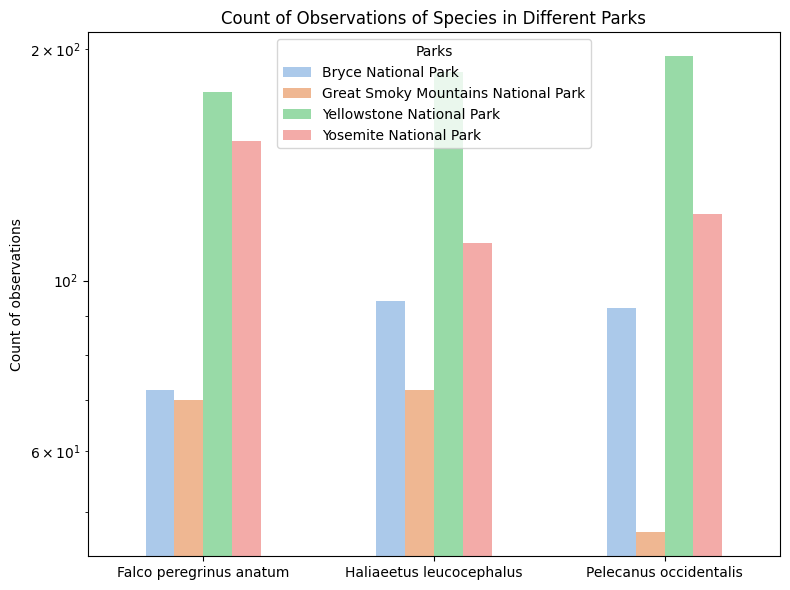

In [37]:
grouped = birds_in_recovery.groupby(['scientific_name', 'park_name'])['observations'].sum().reset_index()

plt.figure(figsize=(8,6))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.barplot(
    x=grouped['scientific_name'],
    y=grouped['observations'],
    hue=grouped['park_name'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yscale('log')
plt.ylabel('Count of observations')
plt.title('Count of Observations of Species in Different Parks')
plt.legend(title='Parks')
plt.tight_layout()
plt.show()

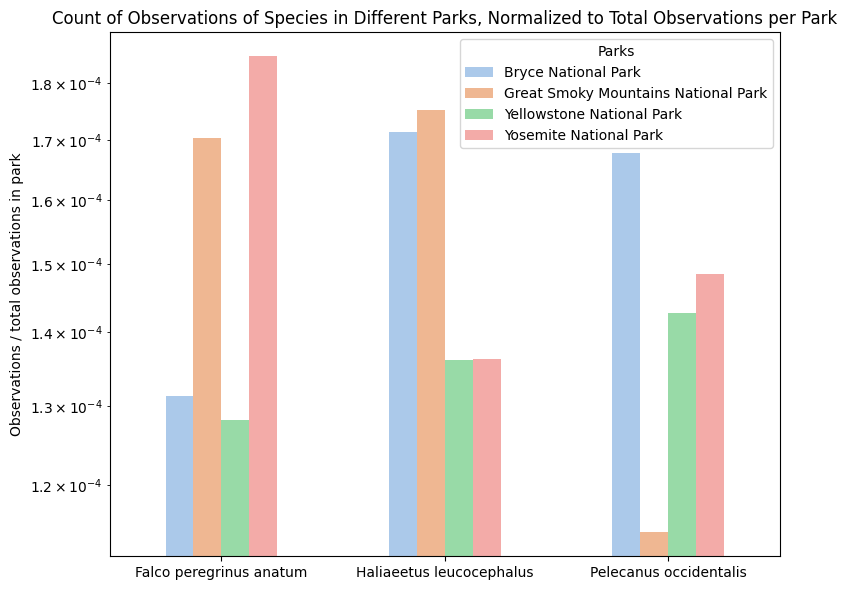

In [38]:
#Once again want to do a normalization step to account for the difference in total observations per park

birds_in_recovery_normalized = pd.merge(birds_in_recovery, total_obs_per_park, on='park_name')
birds_in_recovery_normalized['normalized_observations'] = birds_in_recovery_normalized['observations'] / birds_in_recovery_normalized['total_observations']

plt.figure(figsize=(8,6))
plt.subplots_adjust(hspace=0.25, wspace=0.3)
ax = sns.barplot(
    x=birds_in_recovery_normalized['scientific_name'],
    y=birds_in_recovery_normalized['normalized_observations'],
    hue=birds_in_recovery_normalized['park_name'],
    dodge=True,
    width = 0.5,
    palette='pastel'
)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yscale('log')
plt.ylabel('Observations / total observations in park')
plt.title('Count of Observations of Species in Different Parks, Normalized to Total Observations per Park')
plt.legend(title='Parks')
plt.tight_layout()
plt.show()

As expected, normalization revealed that although Yellowstone might have the highest raw counts of observations for these species, they don't make up a significantly bigger part of the park's total observations when compared to other parks.

Some other interesting findings to note now:
- Observations of Pelecanus occidentalis is very few in Great Smoky Mountains National Park.
- Observations of Falco peregrinus anatum is very high in Yosemite National Park.
- Despite having the most observations among all parks, Yellowstone doesn't seem to contain a particularly high ratio of observations for either of these three species of birds in recovery compared to other parks.
- There is no park that contains the highest number of observations of all three species, instead, each species is observed at the highest ratio in a different park.

My attention is grabbed most by the first observation I made, which is that Pelecanus occidentalis observations are very low in the Great Smoky Mountains. I would like to understand why this may be... I will now shift my focus towards this observation. 

In [39]:
#Let's just focus on this one species for now
pelecanus_occidentalis = birds_in_recovery_normalized[birds_in_recovery_normalized['scientific_name']=='Pelecanus occidentalis']
pelecanus_occidentalis

,category,scientific_name,common_names,conservation_status,park_name,observations,total_observations,normalized_observations
8,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Bryce National Park,92.0,5.482233e+05,0.000168
9,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Great Smoky Mountains National Park,47.0,4.108978e+05,0.000114
10,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Yellowstone National Park,196.0,1.373602e+06,0.000143
11,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Yosemite National Park,122.0,8.215393e+05,0.000149


In order to check whether the difference I observed is statistically significant, I will perform a statistical test. But first, let me re-generate the graph above to only highlight the difference I am interested in, which is the observations of Pelecanus occidentalis being lower in the Great Smoky Mountains compared to OTHER PARKS (later, I will also analyze the difference compared to other species in the same park).

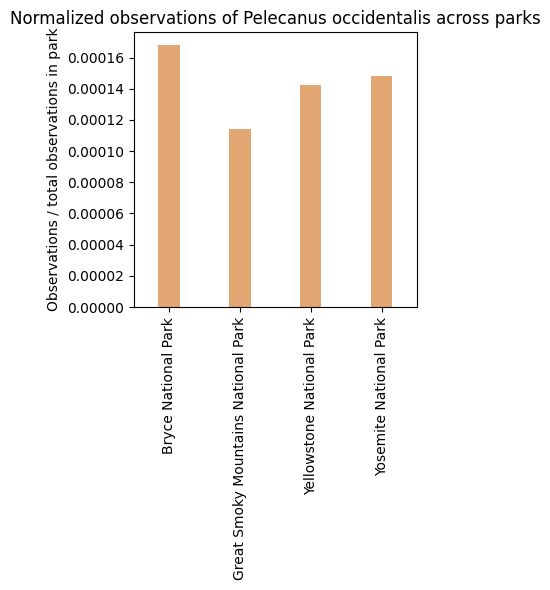

In [40]:
plt.figure(figsize=(4,6))
ax = sns.barplot(
    x=pelecanus_occidentalis['park_name'],
    y=pelecanus_occidentalis['normalized_observations'],
    color='sandybrown',
    width = 0.3,
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.ylabel('Observations / total observations in park')
plt.title('Normalized observations of Pelecanus occidentalis across parks')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In this cleaned up graph, I can visually focus on the difference we're interested in more easily. Let's now perform the test.
First, I will generate my null hypothesis.

Null Hypothesis(𝐻0): There is no significant difference between the observations of Pelecanus occidentalis in Great Smoky Mountains and other parks. i.e. any difference observed is purely due to chance.

Let's see if this is true. I only have one value per park, so a t-test (which needs several measurements in each group to estimate their spread) isn't the right tool here. Instead, my data are counts, so I will use a chi-square test: I compare the number of Brown Pelican observations vs. all other observations in the Great Smoky Mountains against the same numbers in the other three parks. If the pelican made up the same share of observations everywhere, the Great Smoky Mountains count should be close to what that share predicts.

In [41]:
#Count table: Brown Pelican observations vs. all other observations, in Great Smoky Mountains vs. the other three parks
pelican_gsm = pelecanus_occidentalis[pelecanus_occidentalis['park_name']=='Great Smoky Mountains National Park']
pelican_other_parks = pelecanus_occidentalis[pelecanus_occidentalis['park_name']!='Great Smoky Mountains National Park']

pelican_count_gsm = pelican_gsm['observations'].sum()
pelican_count_other = pelican_other_parks['observations'].sum()
all_count_gsm = pelican_gsm['total_observations'].sum()
all_count_other = pelican_other_parks['total_observations'].sum()

contingency_table = [
    [pelican_count_gsm, all_count_gsm - pelican_count_gsm],
    [pelican_count_other, all_count_other - pelican_count_other],
]

from scipy.stats import chi2_contingency

#Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Observed Brown Pelican observations in Great Smoky Mountains:", pelican_count_gsm)
print("Expected if the pelican's share were the same in every park:", round(expected[0][0], 1))
print("chi-square statistic:", chi2)
print("p-value:", p_value)

Observed Brown Pelican observations in Great Smoky Mountains: 47.0
Expected if the pelican's share were the same in every park: 59.5
chi-square statistic: 2.796523937474126
p-value: 0.09446891300335558


Considering this p-value (0.09 > 0.05), we can conclude that the difference noted in the observations of Pelecanus occidentalis in the Great Smoky Mountains National Park compared to other parks is NOT statistically significant: 47 observations is lower than the roughly 60 expected, but not by enough to rule out chance. This means that the difference observed could be due to random variation or limitation of sampling. Good to know!

But what about the difference of the observations of this species compared to other species in the Great Smoky Mountains??? 

Now, I want to compare the observations of Pelecanus occidentalis in the Great Smoky Mountains to OTHER SPECIES at the same park. Let me generate another simplified/cleaned up graph that now highlights this difference in question:

In [42]:
#Let's just focus on the Great Smoky Mountains National Park now...
gsm = birds_in_recovery_normalized[birds_in_recovery_normalized['park_name']=='Great Smoky Mountains National Park']
gsm

,category,scientific_name,common_names,conservation_status,park_name,observations,total_observations,normalized_observations
1,Bird,Falco peregrinus anatum,American Peregrine Falcon,In Recovery,Great Smoky Mountains National Park,70.0,410897.833333,0.000170
5,Bird,Haliaeetus leucocephalus,Bald Eagle,In Recovery,Great Smoky Mountains National Park,72.0,410897.833333,0.000175
9,Bird,Pelecanus occidentalis,Brown Pelican,In Recovery,Great Smoky Mountains National Park,47.0,410897.833333,0.000114


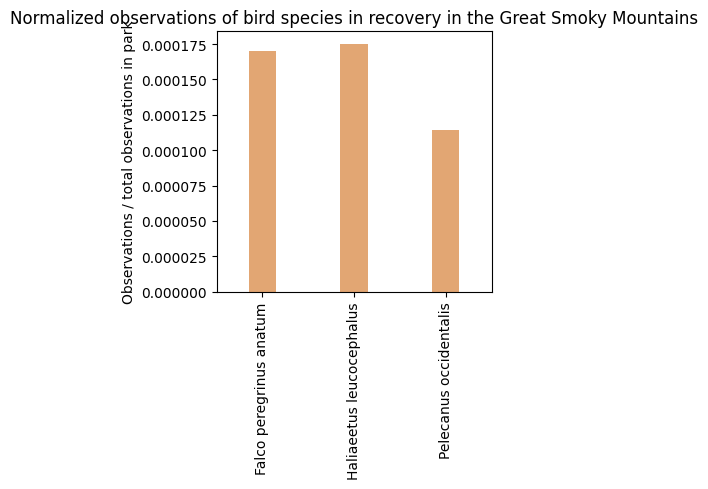

In [43]:
plt.figure(figsize=(4,5))
ax = sns.barplot(
    x=gsm['scientific_name'],
    y=gsm['normalized_observations'],
    color='sandybrown',
    width = 0.3,
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.ylabel('Observations / total observations in park')
plt.title('Normalized observations of bird species in recovery in the Great Smoky Mountains')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

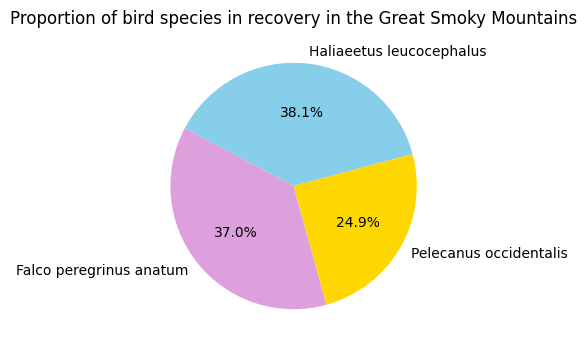

In [44]:
#Another way to show the same data (piechart) that I actually prefer:
def find_total_obs(species):
    rows_in_species = gsm[gsm['scientific_name'] == species]
    total_obs = rows_in_species['observations'].sum()
    return total_obs

bird_species = ['Haliaeetus leucocephalus', 'Falco peregrinus anatum', 'Pelecanus occidentalis']
bird_species_obs = []
for spec in bird_species:
    total_observations = find_total_obs(spec)
    bird_species_obs.append(total_observations)

colors = ['skyblue', 'plum', 'gold']

plt.figure(figsize=(4,4))
plt.pie(
    bird_species_obs,
    labels=bird_species,
    colors=colors,
    autopct='%1.1f%%',
    startangle=15,
)

plt.title('Proportion of bird species in recovery in the Great Smoky Mountains')
plt.show()

New Null Hypothesis(𝐻0): There is no significant difference between the observations of Pelecanus occidentalis and other in-recovery bird species in the Great Smoky Mountains National Park.

Since all three species are in the same park, I can compare their raw observation counts directly (normalizing by the park total would divide all three by the same number). I will use a chi-square goodness-of-fit test, which checks whether the three counts are consistent with all three species being observed equally often.

In [45]:
#Observations of the three in-recovery bird species in the Great Smoky Mountains
gsm_counts = gsm['observations']

from scipy.stats import chisquare

#Perform chi-square goodness-of-fit test (the default expectation is that all three species are observed equally often)
chi2, p_value = chisquare(gsm_counts)

print("Observed counts:", list(gsm_counts))
print("Expected count for each species if equal:", round(gsm_counts.mean(), 1))
print("chi-square statistic:", chi2)
print("p-value:", p_value)

Observed counts: [70.0, 72.0, 47.0]
Expected count for each species if equal: 63.0
chi-square statistic: 6.1269841269841265
p-value: 0.04672424596497046


Interesting! Now, the p-value (0.047 < 0.05) indicates that this difference IS statistically significant, although only just: the Brown Pelican was observed 47 times, compared to an expected 63 if all three species were equally common. (Both tests assume that every observation is independent, which is a simplification for real wildlife survey data.)

Finally, before I conclude this project, I want to shift my focus to bird species that don't have a recorded conservation status. Previously, I ignored these species because I was interested specifically in birds in recovery. However, I did notice that there are many bird species observed that don't have a conservation status noted, and I don't want to overlook this aspect of the data. 

First, I want to see how much of the birds population this group makes.

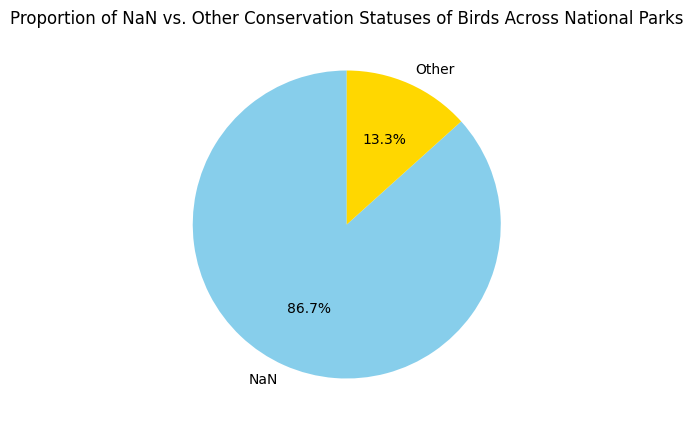

In [46]:
birds_nan = birds[birds['conservation_status'].isna()]
birds_other = birds[birds['conservation_status'].notna()]
birds_nan_count = birds_nan['observations'].sum()
birds_other_count = birds_other['observations'].sum()
def find_total_obs(cons):
    if cons == 'NaN':
        return birds_nan_count
    else:
        return birds_other_count

obs_values = [birds_nan_count, birds_other_count]
labels = ['NaN', 'Other']

colors = ['skyblue', 'gold']

plt.figure(figsize=(5,5))
plt.pie(
    obs_values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
)

plt.title('Proportion of NaN vs. Other Conservation Statuses of Birds Across National Parks')
plt.show()

Almost 90% of all birds have 'NaN' as their conservation_status; it is a very good thing I didn't completely ignore this population. 

Since I'm still hesitant to assign any conservation status to these species, I will simply investigate this group in itself. Since they make up such a large chunk of all birds, I am assuming their distribution and patterns will be similar to the birds population in general. But still, I will start by observing their distribution across parks.

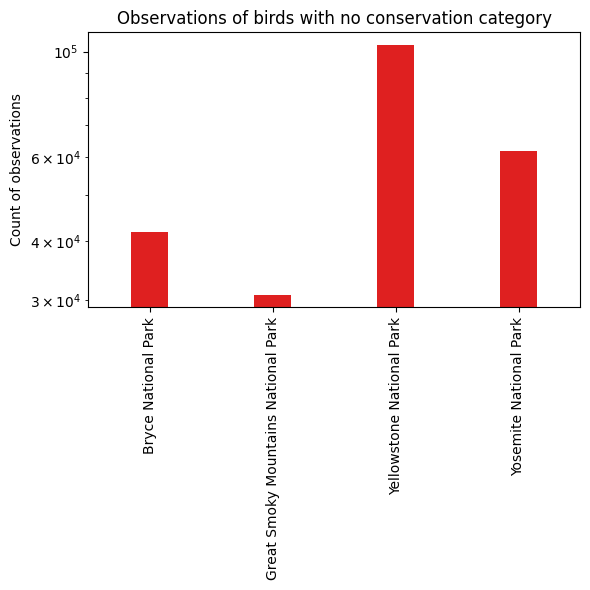

In [47]:
plt.figure(figsize=(6,6))
ax = sns.barplot(
    x=birds[birds['conservation_status'].isna()]['park_name'],
    y=birds[birds['conservation_status'].isna()]['observations'],
    color='red',
    width = 0.3,
    estimator='sum',
    errorbar=None
)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yscale('log')
plt.ylabel('Count of observations')
plt.title('Observations of birds with no conservation category')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

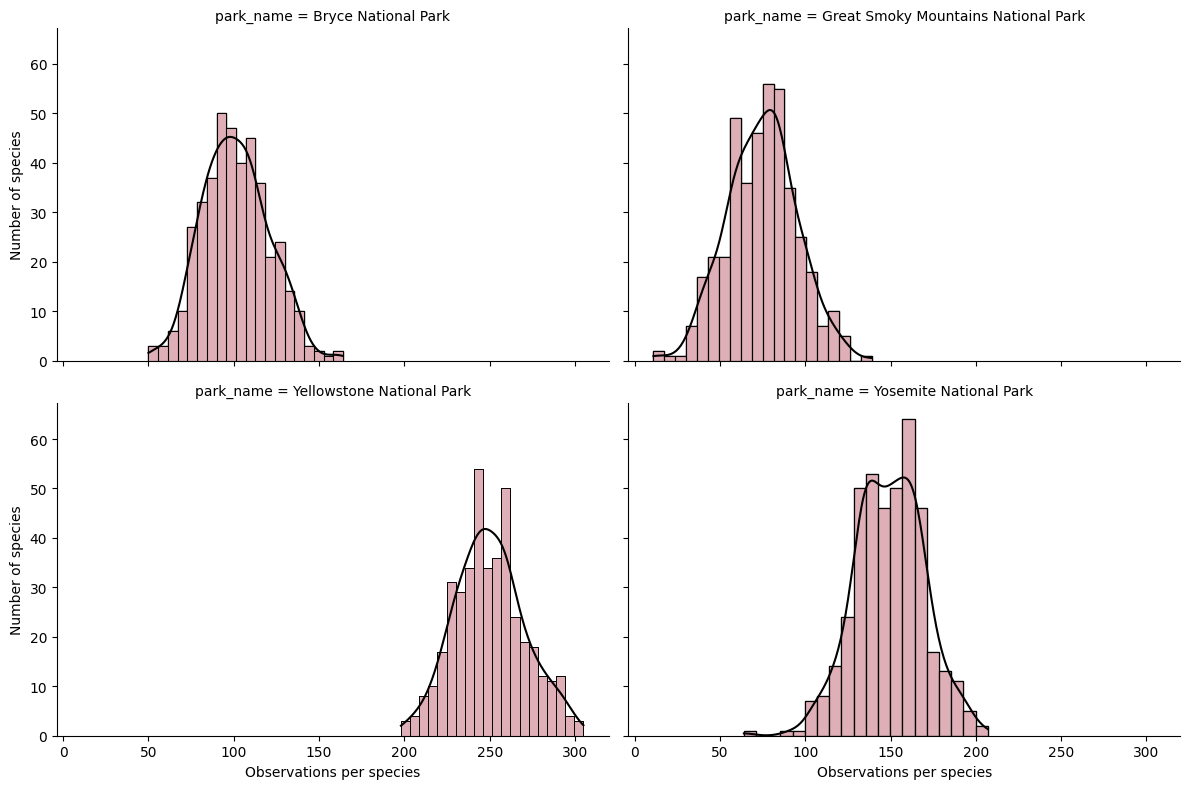

In [48]:
#Distribution of birds_nan observations in each park
g = sns.FacetGrid(
    birds_nan,
    col = 'park_name',
    col_wrap = 2,
    height = 4,
    aspect = 1.5
)
g.map(sns.histplot, 'observations', bins=20, kde=True, color='black') #setting the kde line color first
g.map(sns.histplot, 'observations', bins=20, kde=False, color='pink') #bars color here
g.set_axis_labels('Observations per species', 'Number of species')

plt.show()

All the parks seem to have a similar, bell-curve-like distribution with a similar spread, but the curves are shifted: a typical bird species was observed around 250 times in Yellowstone, around 150 times in Yosemite, around 100 times in Bryce and around 80 times in the Great Smoky Mountains. This matches the order of total observations in each park. 
This concludes my investigation of the 'NaN' conservation category of birds.